**STATISTICS BASICS**

In [1]:
import pandas as pd

df = pd.read_csv("train.csv")

print("Mean:", df["SalePrice"].mean())
print("Median", df["SalePrice"].median())
print("Mode", df["SalePrice"].mode()[0])

Mean: 180921.19589041095
Median 163000.0
Mode 140000


*The mean is higher than the median because some few expensive houses pulled the mean value upwards. Because of this, the median is a better way to describe a house*

**CHECK TO PROVE THAT A HIGHER VALUE PULLS THE MEAN; LEAVING OUTHOUSES OVER 500,000**

In [2]:
cheaper = df[df["SalePrice"] < 500000]["SalePrice"]
print("Mean without the priciest houses:", cheaper.mean())
print("Median without them:", cheaper.median())

Mean without the priciest houses: 178272.87250172294
Median without them: 162500.0


*The mean (180,921) is higher than the median (163,000) because the prices have a long upper tail. Removing the priciest houses moves the mean much more than the median, but a gap remains, so the skew runs through the whole range. The median describes a typical house better.*

**STANDARD DEVIATION**

In [4]:
m = df["SalePrice"].mean()
s = df["SalePrice"].std()

print("Mean:", round(m))
print("Standard deviation:", round(s))

within = df[(df["SalePrice"] > m - s) & (df["SalePrice"] < s + m)]
print("Share of houses within one standard deviation of the mean:", round(len(within) / len(df) * 100, 1), "%")

Mean: 180921
Standard deviation: 79443
Share of houses within one standard deviation of the mean: 78.4 %


*The prices are moderately spread. The standard deviation(79,443) is about 44% of the mean, and about 78% of the houses fall within one standard deviation of the mean. This make it more than a bell-shapped distribution because most of the prices bunch near the middle while a long tail of expensive houses stretches to the right.*

**SEE A HISTOGRAM OF WHAT THE NUMBERS DESCRIBE**

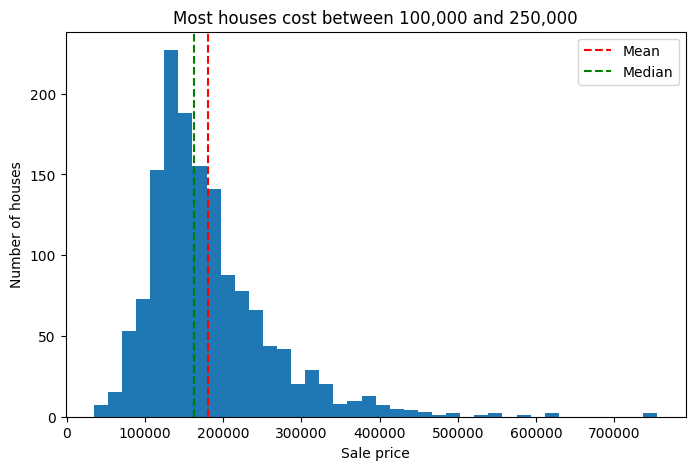

In [6]:
from matplotlib.lines import lineStyles
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df["SalePrice"], bins=40)
plt.axvline(df["SalePrice"].mean(), color="red", linestyle = "--", label = "Mean")
plt.axvline(df["SalePrice"].median(), color="green", linestyle = "--", label = "Median")
plt.title("Most houses cost between 100,000 and 250,000")
plt.xlabel("Sale price")
plt.ylabel("Number of houses")
plt.ticklabel_format(style = "plain", axis = "x")
plt.legend()
plt.show()

*The prices are right-skewed: most houses sell between 100,000 and 200,000, but a long tail of expensive houses stretches to the right. This pulls the mean (red line) above the median (green line).*